- Configuration & Imports

In [1]:
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 📍 Adapter le chemin si ton notebook est dans un sous-dossier
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = next(
    p for p in [NOTEBOOK_DIR] + list(NOTEBOOK_DIR.parents) 
    if (p / "src").exists() and (p / "data").exists()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"✅ Root projet détecté : {PROJECT_ROOT}")

# Imports de tes modules
from src.O3_radiomics.build_ml_dataset import main as build_ml_dataset
from src.O3_radiomics.feature_selector import RadiomicsFeatureSelector
from src.O4_classical_classifier.train_classifier import ClassicalClassifierTrainer
from src.O4_classical_classifier.predict_classifier import ClassicalClassifierPredictor

✅ Root projet détecté : e:\Projet_fin_semestre\FUMPE_Detection\Projet_Detection_Embolie_Pulmonaire


- Génération / Chargement du Dataset Équilibré

In [2]:
DATASET_PATH = PROJECT_ROOT / "data" / "processed" / "ml_dataset_balanced.csv"

if not DATASET_PATH.exists():
    print("⚠️ Dataset équilibré introuvable. Génération en cours...")
    # Force le script O3 à s'exécuter dans le bon contexte
    import importlib
    import src.O3_radiomics.build_ml_dataset as bmd
    importlib.reload(bmd)
    bmd.PROJECT_ROOT = PROJECT_ROOT
    bmd.main()
    
df = pd.read_csv(DATASET_PATH)
print(f"✅ Dataset chargé : {df.shape[0]} candidats")
print(f"📊 Distribution : {df['has_embolism'].value_counts().to_dict()}")
df.head()

INFO:src.O3_radiomics.feature_extractor:✅ Extracteur léger (scikit-image) initialisé.
INFO:src.O3_radiomics.build_ml_dataset:🚀 Construction dataset ML sur 35 patients...


⚠️ Dataset équilibré introuvable. Génération en cours...


INFO:src.O3_radiomics.build_ml_dataset:🎉 DATASET GÉNÉRÉ : e:\Projet_fin_semestre\FUMPE_Detection\Projet_Detection_Embolie_Pulmonaire\data\processed\ml_dataset_balanced.csv
INFO:src.O3_radiomics.build_ml_dataset:   📊 Total: 352 | VP: 40 | FP: 312 | Ratio: 11.36%


✅ Dataset chargé : 352 candidats
📊 Distribution : {0: 312, 1: 40}


,PatientID,candidate_id,has_embolism,intensity_mean,intensity_median,intensity_std,intensity_variance,intensity_min,intensity_max,intensity_skewness,...,shape_major_axis_length,shape_minor_axis_length,shape_elongation,shape_surface_area_mm2,shape_sphericity,texture_contrast,texture_dissimilarity,texture_homogeneity,texture_energy,texture_correlation
0,PAT001,PAT001_GT,1,-381.719025,-600.000000,338.274445,114429.609375,-600.000000,373.792572,1.129079,...,73.582002,16.226438,0.220522,3639.435652,0.257298,2.085452,0.500774,0.865831,0.792512,0.730398
1,PAT001,PAT001_O2_1,0,240.902481,213.542496,109.290527,11944.419922,83.127747,600.000000,1.125011,...,12.440075,8.458557,0.679944,220.857488,0.721485,9.011751,2.381165,0.318457,0.143142,0.471134
2,PAT001,PAT001_O2_2,0,258.313904,236.229462,126.041130,15886.366211,65.656746,588.594360,0.728981,...,10.259299,4.612142,0.449557,109.298038,0.837289,21.324952,3.506694,0.279230,0.169491,0.357001
3,PAT001,PAT001_O2_3,0,186.732712,183.496185,23.630341,558.393005,136.788651,225.755371,0.054407,...,4.623746,2.886751,0.624332,24.978483,1.000000,0.688194,0.625694,0.693403,0.422486,0.391488
4,PAT001,PAT001_O2_4,0,192.208054,184.541061,49.740902,2474.157471,102.243668,330.025482,0.585493,...,14.638772,3.410182,0.232955,173.313914,0.645355,2.241859,1.132147,0.541675,0.205574,0.715362


In [3]:
# Séparation features / label
ID_COL = 'candidate_id'
LABEL_COL = 'has_embolism'
FEATURE_COLS = [c for c in df.columns if c not in [ID_COL, 'PatientID', LABEL_COL]]

X = df[FEATURE_COLS].fillna(0).replace([np.inf, -np.inf], 0)
y = df[LABEL_COL]

# Pipeline de sélection
selector = RadiomicsFeatureSelector(
    variance_threshold=0.01,
    correlation_threshold=0.95,
    top_k_features=20,
    selection_method='random_forest'
)

X_selected = selector.select(X, y)
FINAL_FEATURES = [c for c in X_selected.columns if c != ID_COL]

print(f"✅ Sélection terminée : {len(FEATURE_COLS)} → {len(FINAL_FEATURES)} features")
print(f"🔍 Features retenues : {FINAL_FEATURES[:5]} ...")

# Sauvegarde intermédiaire pour O4 (le trainer attend un CSV)
TEMP_CSV = PROJECT_ROOT / "data" / "processed" / "temp_selected_features.csv"
X_selected[LABEL_COL] = y
X_selected.to_csv(TEMP_CSV, index=False)

INFO:src.O3_radiomics.feature_selector:✅ Sélecteur initialisé : variance=0.01, correlation=0.95, top_k=20
INFO:src.O3_radiomics.feature_selector:🚀 Démarrage sélection de features...
INFO:src.O3_radiomics.feature_selector:📊 Variance: 20 → 20 features
INFO:src.O3_radiomics.feature_selector:📊 Corrélation (>0.95): 20 → 18 features
INFO:src.O3_radiomics.feature_selector:📊 Random Forest: 18 → 18 features
INFO:src.O3_radiomics.feature_selector:✅ Sélection terminée: 20 → 18 features


✅ Sélection terminée : 20 → 18 features
🔍 Features retenues : ['intensity_min', 'texture_correlation', 'intensity_variance', 'shape_minor_axis_length', 'shape_volume_mm3'] ...


Entraînement des Classifieurs (O4)

In [4]:
trainer = ClassicalClassifierTrainer(
    features_path=str(TEMP_CSV),
    label_column=LABEL_COL,
    train_ratio=0.7,
    n_splits=5,
    random_state=42
)

# Entraînement de tous les modèles
models_to_test = ['random_forest', 'xgboost', 'logistic_regression']
results = trainer.train_all(models_to_test)

# Sauvegarde en production
MODELS_DIR = PROJECT_ROOT / "results" / "classical_classifier" / "models"
RESULTS_CSV = PROJECT_ROOT / "results" / "classical_classifier" / "results.csv"

trainer.save_models(str(MODELS_DIR))
trainer.save_results(str(RESULTS_CSV))

print("✅ Entraînement terminé & modèles sauvegardés.")

INFO:src.O4_classical_classifier.train_classifier:✅ Classificateur initialisé : e:\Projet_fin_semestre\FUMPE_Detection\Projet_Detection_Embolie_Pulmonaire\data\processed\temp_selected_features.csv
INFO:src.O4_classical_classifier.train_classifier:📥 Chargement des données depuis e:\Projet_fin_semestre\FUMPE_Detection\Projet_Detection_Embolie_Pulmonaire\data\processed\temp_selected_features.csv...
INFO:src.O4_classical_classifier.train_classifier:📊 Features: 18, Samples: 352, Positives: 40
INFO:src.O4_classical_classifier.train_classifier:🔄 Validation croisée pour random_forest...
INFO:src.O4_classical_classifier.train_classifier:🚀 Entraînement de random_forest...
INFO:src.O4_classical_classifier.train_classifier:✅ random_forest entraîné
INFO:src.O4_classical_classifier.train_classifier:  Fold 1: AUC=1.000, F1=0.941
INFO:src.O4_classical_classifier.train_classifier:🚀 Entraînement de random_forest...
INFO:src.O4_classical_classifier.train_classifier:✅ random_forest entraîné
INFO:src.O4_cl

✅ Entraînement terminé & modèles sauvegardés.


Évaluation & Visualisation

                     auc_roc     f1  recall  precision  accuracy
random_forest          0.970  0.800   0.725      0.949     0.963
xgboost                0.970  0.814   0.750      0.928     0.963
logistic_regression    0.956  0.776   0.800      0.772     0.949


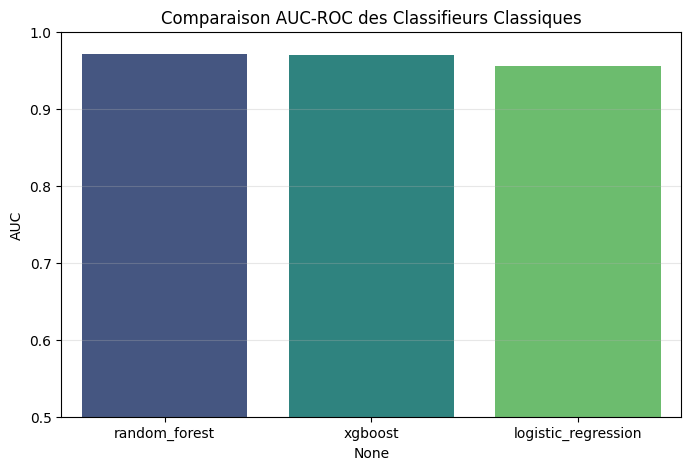

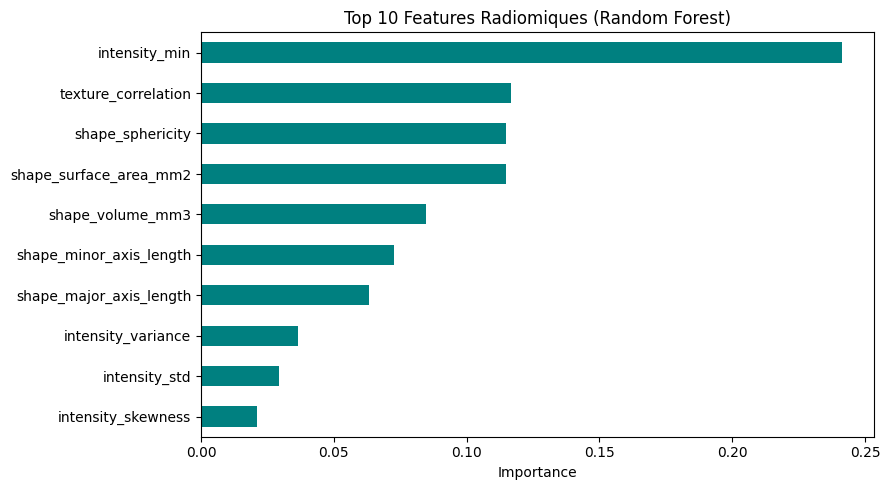

In [5]:
# Tableau comparatif
df_res = pd.DataFrame(results).T
metrics_order = ['auc_roc', 'f1', 'recall', 'precision', 'accuracy']
print(df_res[metrics_order].round(3))

# 📈 Courbe comparative AUC
plt.figure(figsize=(8, 5))
sns.barplot(x=df_res.index, y='auc_roc', data=df_res, palette='viridis')
plt.title('Comparaison AUC-ROC des Classifieurs Classiques')
plt.ylabel('AUC')
plt.ylim(0.5, 1.0)
plt.grid(axis='y', alpha=0.3)
plt.show()

# 📊 Feature Importance (si Random Forest)
if 'random_forest' in trainer.models:
    rf = trainer.models['random_forest']
    importances = rf.feature_importances_
    feat_imp = pd.Series(importances, index=FINAL_FEATURES).nlargest(10)
    
    plt.figure(figsize=(9, 5))
    feat_imp.sort_values().plot(kind='barh', color='teal')
    plt.title('Top 10 Features Radiomiques (Random Forest)')
    plt.xlabel('Importance')
    plt.tight_layout()
    plt.show()